# 01 · Preprocessing — malignant manifold (Zhang et al. 2019, Follicular Lymphoma)

Follicular lymphoma / transformed DLBCL, 10x, **4 malignant samples from 2 patients**
(FL1018, FL2001 — each a primary + a transformed/progressed timepoint). All profiled cells are
malignant B cells (the publication's `cell_type == 'Malignant'`). We load the malignant compartment,
threshold thin samples by a **data-driven gap check**, integrate over `sample` with Harmony,
embed, remove detached islands, settle sub-region biology, and read **Gate 1** (sample-mixing +
manifold continuity) off the **regenerated embedding across an integration-strength (theta) sweep**
with a per-neighbourhood metric (**iLISI**) — never a global scalar. The two patients carry distinct
clonal/CNV backgrounds, so raw patient segregation is expected and strong integration is required.
Every tunable choice is *derived from this dataset* (C1-C4), not inherited from the Puram2017
skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Zhang2019_Hematologic-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
# input folder = dataset name minus the '-2' re-analysis suffix
raw_name = 'Data_' + name.replace('-2', '')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Zhang2019_Hematologic-2 | category: Hematologic | raw: Data_Zhang2019_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total + `log1p`, and
reads the publication `cell_type`. Zhang 2019 annotates malignant B cells vs a small normal
T/B compartment; we keep the publication's malignant call (`celltype == 'Malignant'`).

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('samples:', adata.obs['sample'].value_counts().to_dict())
print('progression:', adata.obs['progression_status'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas: (7002, 24410)
cell types: {'Malignant': 5645, 'T_cell': 843, 'B_cell': 494}
malignant: (5645, 24410) | samples: 4 | patients: 2
samples: {'FL1018T2': 2405, 'FL2001T2': 1876, 'FL2001T1': 684, 'FL1018T1': 680}
progression: {'transformed (DLBCL)': 2405, 'progressed': 1876, 'primary': 1364}
expression: X max 7.33 (log1p of normalize_total UMI counts)


### Per-sample cell-count threshold (data-driven, C3/C4)
Sort per-sample malignant counts and look for a **dominant spillover cliff** — a ratio gap that
both dwarfs the runner-up gap (`top/second >= 1.5`) *and* drops a sample into the sub-viable range
(`< 2*FLOOR`). Only then is a geometric-mean threshold justified; otherwise the "clean count gap"
assumption fails and the rule falls back to the viability floor (>=100 cells). Here all four
samples are well populated (680-2405 cells) with no sub-viable sample, so **no dominant cliff
exists** and the floor keeps all four.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant cliff -> geometric-mean threshold = %d' % thresh) if dominant
      else f'no dominant cliff (all samples well-populated) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'FL1018T2': np.int64(2405), 'FL2001T2': np.int64(1876), 'FL2001T1': np.int64(684), 'FL1018T1': np.int64(680)}
gap ratios: ['2405->1876:1.28', '1876->684:2.74', '684->680:1.01']
argmax gap 1876->684 (ratio 2.74); top/second = 2.14; dominant cliff = False
no dominant cliff (all samples well-populated) -> floor >= 100
kept 4/4 samples (min per-sample = 680) -> 5645 cells


### Gene filter, overdispersion, PCA, Harmony integration sweep
Filter genes, select overdispersed features, PCA (**no `sc.pp.scale` before PCA** — absent from the
reference protocol and a documented cause of false NO-GOs). `n_pcs=30`, `n_neighbors=30` (mid of the
robust 20-40 range). Integration strength is swept over `theta` and judged by **iLISI** (inverse-
Simpson effective #samples per neighbourhood) against the perfect-mixing ceiling — the per-
neighbourhood metric the spec requires. iLISI rises to a plateau at theta=10 then declines
(theta=20/40 over-integrate), so theta=10 is the strongest integration without collapse.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP, NN = 30, 30
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum(); out[i] = 1.0/np.sum(p**2)
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 20, 40]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(iLISI peaks at 10 then declines at 20/40; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
#samples=4 | iLISI ceiling (perfect mixing) = 3.11
iLISI | pre-Harmony 1.05 | sweep {1: np.float64(1.31), 2: np.float64(1.34), 5: np.float64(1.8), 10: np.float64(1.88), 20: np.float64(1.85), 40: np.float64(1.64)}
selected theta = 10 (iLISI peaks at 10 then declines at 20/40; strongest integration without collapse)


### Integration-strength sweep — the Gate-1 evidence (embedding, not a scalar)
The three-column sweep is the decisive Gate-1 read. At **theta=1** the manifold is a per-patient
archipelago (two fully separate blobs); by **theta=5** the two patients begin to interleave; at
**theta=10** all four samples and both patients intermix across one continuous connected mass.

theta=1: two separate patient blobs; theta=10: all 4 samples + both patients on one connected mass.


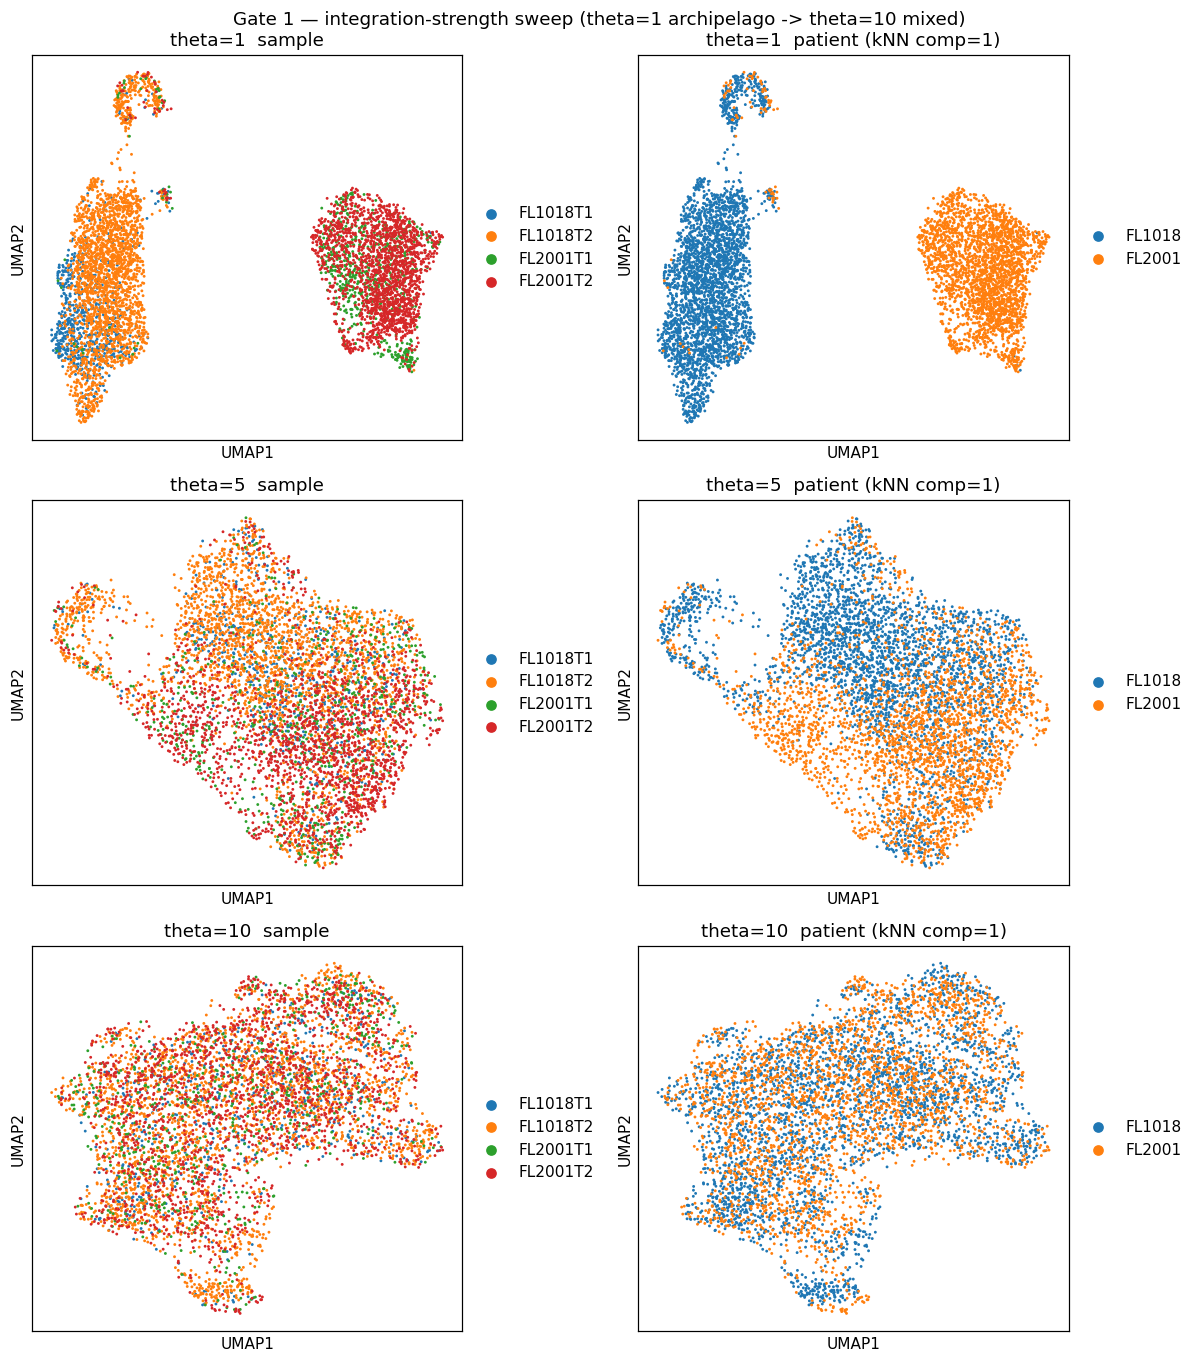

In [6]:
thetas = [1, 5, 10]
fig, axes = plt.subplots(len(thetas), 2, figsize=(11, 4.2*len(thetas)))
for r, th in enumerate(thetas):
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    nc = connected_components(adata.obsp['connectivities'], directed=False)[0]
    sc.pl.umap(adata, color='sample',  size=14, ax=axes[r,0], show=False, title=f'theta={th}  sample')
    sc.pl.umap(adata, color='patient', size=14, ax=axes[r,1], show=False, title=f'theta={th}  patient (kNN comp={nc})')
fig.suptitle('Gate 1 — integration-strength sweep (theta=1 archipelago -> theta=10 mixed)', size=12)
fig.tight_layout()
print('theta=1: two separate patient blobs; theta=10: all 4 samples + both patients on one connected mass.')

### Commit theta=10; remove detached islands (radius-graph connected components)
Re-embed at the selected theta=10, then build a UMAP radius graph at 6x the median nearest-
neighbour distance and keep the largest connected component. Strictly conservative — strips only
disconnected specks.

In [7]:
theta = 10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab != main).sum())
print('removed', n_removed, 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
kncomp = connected_components(adata.obsp['connectivities'], directed=False)[0]
print('after removal: kNN connected components =', kncomp, '| cells =', adata.shape[0])

removed 0 cells in 0 detached islands
after removal: kNN connected components = 1 | cells = 5645


### Sub-region biology before the Gate-1 GO (Kürten lobe-identity fork)
Low-resolution Leiden resolves the manifold into lobes; each is annotated by cell-cycle occupancy
and a proliferation score. The only distinct sub-structure is a small **high-cycling pocket**
(labelled `Cycling`); it is not a disconnected island or a separate lineage (both patients
populate every lobe). Making the proliferation split explicit lets the trajectory step confirm the
developmental axis runs *across* the manifold rather than being driven by cycling.

In [8]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
hi_lobe = cyc.idxmax()
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('patient mix per lobe:')
print(pd.crosstab(adata.obs['lobe'], adata.obs['patient']).to_string())
lab_map = {l: ('Cycling' if l == hi_lobe else 'Non-cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 2971, '3': 1431, '2': 807, '0': 234, '4': 202}
cycling fraction per lobe: {'0': 0.252, '1': 0.073, '2': 0.047, '3': 0.198, '4': 0.965}
proliferation score per lobe: {'0': 0.006, '1': -0.034, '2': -0.04, '3': 0.013, '4': 0.785}
patient mix per lobe:
patient  FL1018  FL2001
lobe                   
0           150      84
1          1603    1368
2           401     406
3           783     648
4           148      54
compartments: {'Non-cycling': 5443, 'Cycling': 202}


### Gate 1 — mixing and continuity, judged on the regenerated embedding
The diagnostic colours the committed (theta=10) embedding by sample, compartment and cell-cycle
phase. All four samples and both patients intermix across one connected mass; per-neighbourhood
iLISI rises from the pre-Harmony value to its plateau at theta=10; the radius graph leaves a single
component and the kNN graph is connected. **Mixed AND continuous -> Gate 1 GO.**

4 samples + both patients share one continuous manifold; iLISI reaches 1.88 of 3.11 ceiling at the theta=10 plateau.
radius-graph detached islands: 0 | kNN connected components: 1
Gate 1: samples intermixed on one continuous manifold -> GO


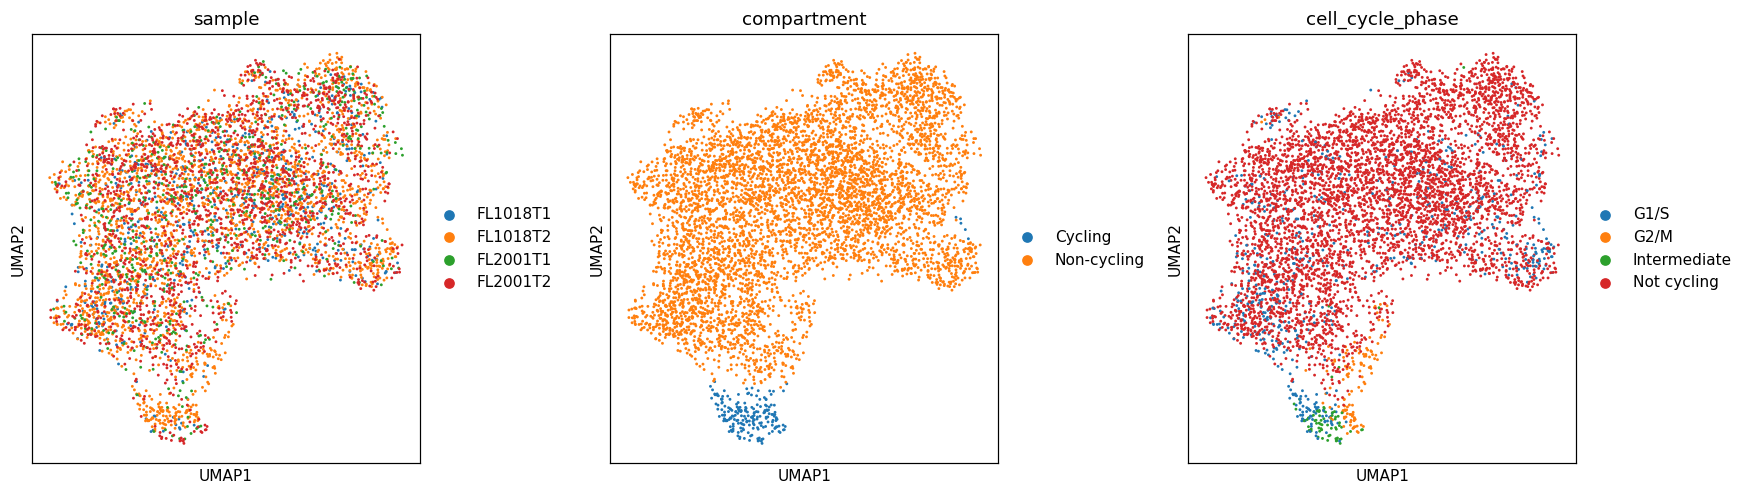

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sc.pl.umap(adata, color='sample',           size=14, ax=axes[0], show=False, title='sample')
sc.pl.umap(adata, color='compartment',       size=14, ax=axes[1], show=False, title='compartment')
sc.pl.umap(adata, color='cell_cycle_phase',  size=14, ax=axes[2], show=False, title='cell_cycle_phase')
fig.tight_layout()
print(f'{adata.obs["sample"].nunique()} samples + both patients share one continuous manifold; '
      f'iLISI reaches {sweep[theta]:.2f} of {ceiling:.2f} ceiling at the theta=10 plateau.')
print('radius-graph detached islands:', n_removed, '| kNN connected components:', kncomp)
print('Gate 1: samples intermixed on one continuous manifold -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Deliverable — `samples.pdf` (single sample-coloured manifold UMAP)
House style `figsize=(3.5,1.5)`, `size=30`; colour = sample. Intermixing of all four samples across
one continuous manifold is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 5645


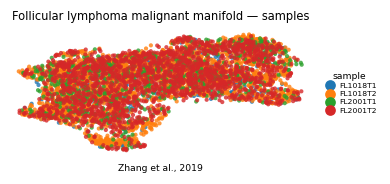

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Follicular lymphoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])